<h1 style="color:#235d89">Método de Neville</h1>

**Métodos Numéricos I — ESFM**  
**Burden, algoritmo 3.1 — Ejemplo 2**

## 1. Planteamiento

Se desea aproximar $f(1.5)$ a partir de los valores de la tabla del **ejemplo 2**.

| $x_i$ | $f(x_i)$ |
|:---:|---:|
| 1.0 | 0.7651977 |
| 1.3 | 0.6200860 |
| 1.6 | 0.4554022 |
| 1.9 | 0.2818186 |
| 2.2 | 0.1103623 |

$$\boxed{x=1.5}$$

## 2. Método de Neville

Los datos forman la primera columna de la tabla:

$$Q_{i,0}=f(x_i)$$

La fórmula recursiva del algoritmo 3.1 es

$$\boxed{Q_{i,j}=\frac{(x-x_{i-j})Q_{i,j-1}-(x-x_i)Q_{i-1,j-1}}{x_i-x_{i-j}}}$$

con $i=1,\ldots,n$ y $j=1,\ldots,i$. El último elemento es la aproximación:

$$P(x)=Q_{n,n}.$$

## 3. Código en Python

### Datos del ejemplo

In [1]:
from sympy import *

In [2]:
xi = [1.0, 1.3, 1.6, 1.9, 2.2]
a = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x = 1.5
n = len(xi) - 1

### Construcción de la tabla

`Q[i][j]` representa la entrada $Q_{i,j}$. Con `range` se recorren los índices necesarios.

In [3]:
Q = [[0.0 for j in range(n+1)] for i in range(n+1)]

# Primera columna
for i in range(n+1):
    Q[i][0] = a[i]

In [4]:
# Algoritmo 3.1 de Neville
for i in range(1, n+1):
    for j in range(1, i+1):
        Q[i][j] = ((x-xi[i-j])*Q[i][j-1] - (x-xi[i])*Q[i-1][j-1])/(xi[i]-xi[i-j])

### Tabla obtenida

In [5]:
print(' xi       Q_i,0      Q_i,1      Q_i,2      Q_i,3      Q_i,4')
for i in range(n+1):
    fila = f'{xi[i]:.1f}   '
    for j in range(i+1):
        fila += f'  {Q[i][j]:.7f}'
    print(fila)

 xi       Q_i,0      Q_i,1      Q_i,2      Q_i,3      Q_i,4
1.0     0.7651977
1.3     0.6200860  0.5233449
1.6     0.4554022  0.5102968  0.5124715
1.9     0.2818186  0.5132634  0.5112857  0.5118127
2.2     0.1103623  0.5104270  0.5137361  0.5118302  0.5118200


### Resultado

In [6]:
print(f'P({x}) = Q[{n}][{n}] = {Q[n][n]:.7f}')

P(1.5) = Q[4][4] = 0.5118200


La última entrada de la tabla corresponde a la aproximación con los cinco nodos.

$$\boxed{P(1.5)\approx 0.5118200}$$

## 4. Gráfica del polinomio interpolador

Para dibujar la curva, se utiliza la misma recurrencia con una variable simbólica `t`, en lugar de evaluar únicamente en `x = 1.5`.

In [7]:
t = symbols('t')
S = [[0 for j in range(n+1)] for i in range(n+1)]
for i in range(n+1):
    S[i][0] = a[i]

for i in range(1, n+1):
    for j in range(1, i+1):
        S[i][j] = ((t-xi[i-j])*S[i][j-1] - (t-xi[i])*S[i-1][j-1])/(xi[i]-xi[i-j])

In [8]:
p = expand(S[n][n])
p

0.00182510288065989*t**4 + 0.0552927983538989*t**3 - 0.343046604938245*t**2 + 0.0733913477365975*t + 0.977735055967089

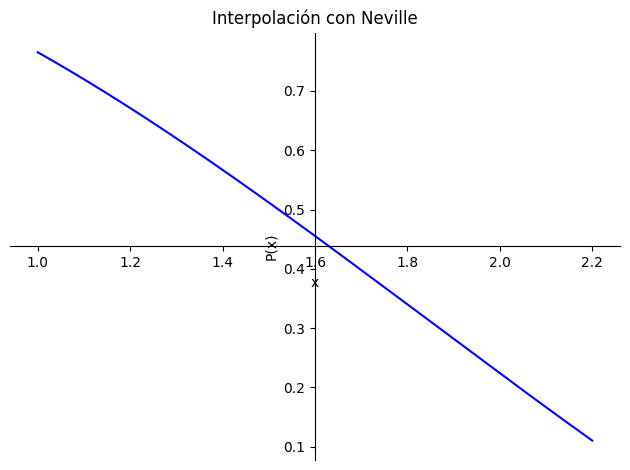

In [9]:
plotting.plot(p, (t, 1.0, 2.2), title='Interpolación con Neville',
              xlabel='x', ylabel='P(x)', line_color='blue')

## 5. Conclusión

Con la tabla de Neville se obtiene $Q_{4,4}=0.5118200$, por lo que $f(1.5)\approx0.5118200$. La tabla muestra las aproximaciones obtenidas conforme aumenta el grado de interpolación.

**Referencia:** Burden, Faires y Burden, *Análisis numérico*, 10.ª edición, sección 3.2, ejemplo 2 y algoritmo 3.1.